
# Aetheria
## Environmental Data Analytics and Weather Intelligence System

**Project Domain:** Environmental Data Analytics

**Programming Language:** Python

**Libraries:** Pandas, NumPy, Matplotlib, Requests, SQLite

**Weather Data Source:** Open-Meteo API

### Abstract

Aetheria is a weather analytics system designed to retrieve weather forecasts for locations around the world, analyse environmental measurements, assess data quality, compare weather conditions across cities, and preserve analysis summaries in a SQLite database.

The system combines statistical analysis, data visualization, rule-based weather insights, and database integration to present weather information in an understandable form.

### Objectives

1. Retrieve weather forecast data for selected geographical locations.
2. Calculate descriptive statistics for temperature, humidity, precipitation, and wind speed.
3. identify missing values, duplicate records, and suspicious measurements.
4. Generate visualizations and rule-based weather insights.
5. Compare forecast summaries across multiple cities.
6. Store and retrieve analysis summaries using SQLite.

### Important Data Note

Open-Meteo provides weather forecasts and model-based estimates. These results should not be treated as direct observations from local weather stations or as evidence of long-term climate trends.



## 1. Import Required Libraries

This section imports the Python libraries used for retrieving, processing, analysing, and visualizing weather data.

- **Pandas:** tabular data processing and analysis.
- **NumPy:** numerical operations.
- **Matplotlib:** plotting weather trends.
- **Requests:** communicating with the weather API.
- **SQLite:** storing analysis history.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
import sqlite3

from pathlib import Path
from IPython.display import display

print("Aetheria notebook initialized successfully.")

Aetheria notebook initialized successfully.



## 2. Retrieve Weather Forecast Data

Aetheria uses the Open-Meteo Geocoding API to locate a city and the Open-Meteo Forecast API to retrieve its weather data.

The example below analyses a seven-day hourly forecast for Kochi, Kerala. The location can be changed to another city by modifying the search input.


In [2]:
from modules.weather import search_city, get_weather, prepare_weather_data

city_name = "Kochi"

cities = search_city(city_name)

if cities.empty:
    print("No exact city match found. Check the city name.")
else:
    display(cities)

    selected_city = cities.iloc[0]

    current, hourly = get_weather(
        selected_city["Latitude"],
        selected_city["Longitude"],
        selected_city["Time Zone"]
    )

    hourly_clean = prepare_weather_data(hourly)

    print("Selected location:", selected_city["City"], selected_city["Country"])
    print("Hourly forecast records:", len(hourly_clean))

    display(current)
    display(hourly_clean.head())

,City,State / Region,Country,Latitude,Longitude,Population,Time Zone
0,Kochi,Kerala,India,9.93988,76.26022,633553.0,Asia/Kolkata
1,Kochi,Kochi,Japan,33.55000,133.53333,332059.0,Asia/Tokyo
2,Kochi,Ivanovo Oblast,Russia,57.22531,42.33691,NaN,Europe/Moscow
3,Kochi,Maharashtra,India,20.18693,78.45592,NaN,Asia/Kolkata
4,Kochi,Maharashtra,India,20.29374,78.77265,NaN,Asia/Kolkata
5,Kochi,Maharashtra,India,20.82324,79.84512,NaN,Asia/Kolkata
6,Kochi,Maharashtra,India,20.02872,79.12357,NaN,Asia/Kolkata


Selected location: Kochi India
Hourly forecast records: 168


,time,interval,temperature_2m,relative_humidity_2m,apparent_temperature,is_day,precipitation,weather_code,wind_speed_10m
0,2026-10-25T23:45,900,25.2,97,31.3,0,0.1,51,2.7


,time,temperature_2m,relative_humidity_2m,precipitation_probability,precipitation,wind_speed_10m
0,2026-10-25 00:00:00,25.8,97,100,0.4,6.6
1,2026-10-25 01:00:00,25.5,93,99,0.7,7.7
2,2026-10-25 02:00:00,25.4,94,98,6.5,2.1
3,2026-10-25 03:00:00,25.2,96,95,0.9,6.5
4,2026-10-25 04:00:00,24.9,98,92,0.1,9.5



## 3. Descriptive Statistical Analysis

This section calculates summary statistics for the retrieved forecast. The statistics describe the selected forecast window and are not long-term climate averages.


In [3]:
from modules.analytics import (
    calculate_weather_summary,
    calculate_temperature_change
)

summary = calculate_weather_summary(hourly_clean)
temperature_change = calculate_temperature_change(hourly_clean)

summary_df = pd.DataFrame(
    list(summary.items()),
    columns=["Metric", "Value"]
)

display(summary_df)

print("Temperature change across the forecast window:")
display(pd.DataFrame([temperature_change]))

,Metric,Value
0,Average Temperature (°C),26.98
1,Maximum Temperature (°C),30.40
2,Minimum Temperature (°C),24.30
3,Average Humidity (%),86.17
4,Maximum Precipitation Probability (%),100.00
5,Total Precipitation (mm),26.90
6,Average Wind Speed (km/h),6.70


Temperature change across the forecast window:


,First Forecast Temperature (°C),Last Forecast Temperature (°C),Temperature Change (°C)
0,25.8,25.6,-0.2



## 4. Weather Data Quality Assessment

The retrieved forecast is checked for duplicate records, missing values, suspicious temperature measurements, and negative precipitation values. These checks help identify basic data-quality issues before interpreting the results.


In [4]:
from modules.data_quality import check_weather_data

quality = check_weather_data(hourly_clean)

quality_summary = {
    "Total Records": quality["Total Records"],
    "Duplicate Records": quality["Duplicate Records"],
    "Missing Values": quality["Missing Values"],
    "Suspicious Temperatures": quality["Suspicious Temperatures"],
    "Negative Precipitation Records": quality["Negative Precipitation Records"]
}

display(pd.DataFrame(
    list(quality_summary.items()),
    columns=["Quality Check", "Result"]
))

print("Missing values by column:")
display(pd.DataFrame(
    list(quality["Missing Values by Column"].items()),
    columns=["Column", "Missing Values"]
))

,Quality Check,Result
0,Total Records,168
1,Duplicate Records,0
2,Missing Values,0
3,Suspicious Temperatures,0
4,Negative Precipitation Records,0


Missing values by column:


,Column,Missing Values
0,time,0
1,temperature_2m,0
2,relative_humidity_2m,0
3,precipitation_probability,0
4,precipitation,0
5,wind_speed_10m,0



## 5. Weather Forecast Visualization

The following chart displays the hourly temperature forecast over the selected seven-day period. Visualization makes it easier to identify temperature fluctuations and compare warmer and cooler periods.


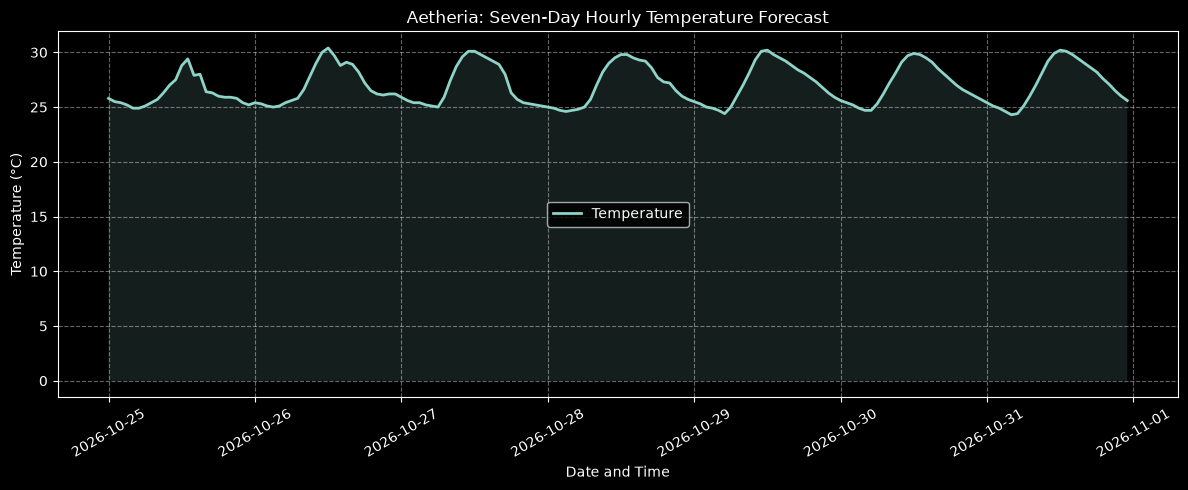

In [5]:
plt.figure(figsize=(12, 5))

plt.plot(
    hourly_clean["time"],
    hourly_clean["temperature_2m"],
    linewidth=2,
    label="Temperature"
)

plt.fill_between(
    hourly_clean["time"],
    hourly_clean["temperature_2m"],
    alpha=0.15
)

plt.xlabel("Date and Time")
plt.ylabel("Temperature (°C)")
plt.title("Aetheria: Seven-Day Hourly Temperature Forecast")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


## 6. Precipitation Probability Analysis

This chart shows the hourly probability of precipitation throughout the forecast period. Probability represents the chance of precipitation, not the expected amount of rainfall.


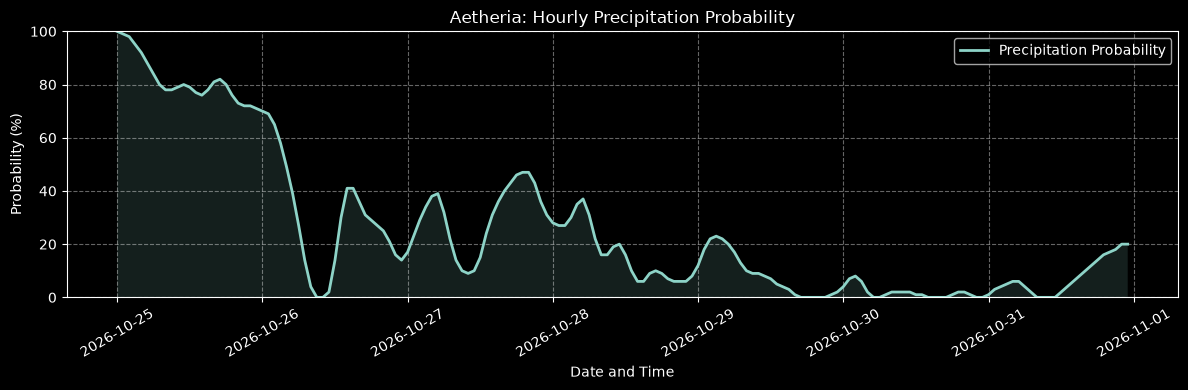

In [7]:
plt.figure(figsize=(12, 4))

plt.plot(
    hourly_clean["time"],
    hourly_clean["precipitation_probability"],
    linewidth=2,
    label="Precipitation Probability"
)

plt.fill_between(
    hourly_clean["time"],
    hourly_clean["precipitation_probability"],
    alpha=0.15
)

plt.xlabel("Date and Time")
plt.ylabel("Probability (%)")
plt.title("Aetheria: Hourly Precipitation Probability")
plt.ylim(0, 100)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


## 7. Rule-Based Weather Risk Assessment

Aetheria applies predefined thresholds to forecast temperature, precipitation probability, hourly precipitation, and wind speed. The resulting score classifies conditions as Low, Moderate, or High risk.

This is an experimental screening indicator for the project, not an official meteorological warning.


In [8]:
from modules.risk_analysis import calculate_weather_risk

risk = calculate_weather_risk(hourly_clean)

risk_summary = {
    "Risk Level": risk["Risk Level"],
    "Risk Score": risk["Risk Score"],
    "Explanation": risk["Explanation"],
    "Maximum Temperature (°C)": risk["Maximum Temperature (°C)"],
    "Maximum Rain Probability (%)": risk["Maximum Rain Probability (%)"],
    "Maximum Hourly Precipitation (mm)": risk["Maximum Hourly Precipitation (mm)"],
    "Maximum Wind Speed (km/h)": risk["Maximum Wind Speed (km/h)"]
}

display(pd.DataFrame(
    list(risk_summary.items()),
    columns=["Assessment", "Result"]
))

print("Conditions identified:")
for reason in risk["Reasons"]:
    print("-", reason)

,Assessment,Result
0,Risk Level,Moderate
1,Risk Score,1
2,Explanation,At least one forecast condition met a selected...
3,Maximum Temperature (°C),30.4
4,Maximum Rain Probability (%),100.0
5,Maximum Hourly Precipitation (mm),6.5
6,Maximum Wind Speed (km/h),14.5


Conditions identified:
- High precipitation probability (80% or above)



## 8. Automated Weather Insights

Aetheria uses predefined rules to convert forecast statistics into readable observations about temperature, humidity, precipitation, and wind speed. These insights explain selected measurements rather than using a trained machine-learning model.


In [9]:
from modules.insights import generate_weather_insights

insights = generate_weather_insights(hourly_clean, summary)

for number, insight in enumerate(insights, start=1):
    print(f"{number}. {insight}")

1. The forecast temperatures do not meet Aetheria's selected high-heat or cold-weather thresholds.
2. Average humidity is high. Conditions may feel more humid than the temperature alone suggests.
3. Some precipitation is forecast. Check hourly rainfall probabilities to understand when rain may occur.
4. Average forecast wind speed is below Aetheria's selected elevated-wind threshold.



## 9. Comparative Weather Analysis Across Cities

This section retrieves forecasts for two locations and compares their average forecast temperature, humidity, accumulated precipitation, and wind speed. Both locations use the same seven-day hourly forecast period where available.

Results represent model-based forecasts, not long-term climate conditions.


In [10]:
comparison_cities = ["Kochi", "Bengaluru"]
comparison_results = []

for city in comparison_cities:
    city_data = search_city(city)

    if city_data.empty:
        print(f"No exact city match found for {city}.")
        continue

    location = city_data.iloc[0]

    current_data, hourly_data = get_weather(
        location["Latitude"],
        location["Longitude"],
        location["Time Zone"]
    )

    clean_data = prepare_weather_data(hourly_data)
    city_summary = calculate_weather_summary(clean_data)

    comparison_results.append({
        "City": location["City"],
        "Country": location["Country"],
        **city_summary
    })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df)

,City,Country,Average Temperature (°C),Maximum Temperature (°C),Minimum Temperature (°C),Average Humidity (%),Maximum Precipitation Probability (%),Total Precipitation (mm),Average Wind Speed (km/h)
0,Kochi,India,26.98,30.4,24.3,86.17,100,26.9,6.7
1,Bengaluru,India,22.58,29.7,17.1,68.52,100,5.7,8.7


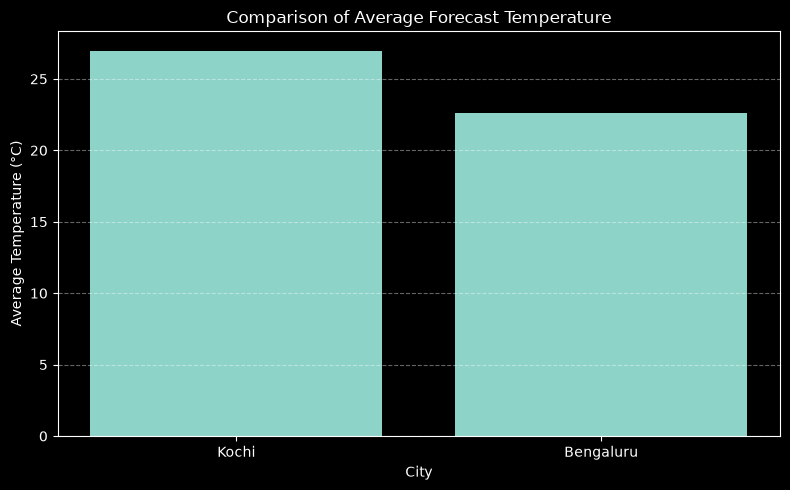

In [11]:
if not comparison_df.empty:
    plt.figure(figsize=(8, 5))

    plt.bar(
        comparison_df["City"],
        comparison_df["Average Temperature (°C)"]
    )

    plt.xlabel("City")
    plt.ylabel("Average Temperature (°C)")
    plt.title("Comparison of Average Forecast Temperature")
    plt.grid(axis="y", linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()


## 10. Database Integration Using SQLite

Aetheria uses SQLite to preserve weather analysis summaries. This allows previously calculated results to be retrieved later without requiring a separate database server.

The following section uses the project's existing database module to save the current city's analysis and retrieve saved records.


In [12]:
from modules.database import create_database, save_analysis, get_saved_analyses

create_database()

save_analysis(
    selected_city["City"],
    selected_city["Country"],
    summary
)

saved_analyses = get_saved_analyses()

print("Saved analysis records:")
display(saved_analyses)

Saved analysis records:


,id,city,country,analysis_time,average_temperature,maximum_temperature,minimum_temperature,average_humidity,total_precipitation,average_wind_speed
0,8,Kochi,India,2026-10-25 18:24:31,26.98,30.4,24.3,86.17,26.9,6.70
1,7,Hyderabad,India,2026-10-25 11:12:52,26.89,32.4,22.5,52.76,2.9,10.38
2,6,Osaka,Japan,2026-10-25 10:40:17,17.03,23.3,8.4,79.82,120.4,5.41
3,5,Saar,Bahrain,2026-10-24 19:42:31,30.81,34.5,27.3,63.50,0.0,9.14
4,4,Manama,Bahrain,2026-10-24 19:41:26,30.87,34.6,27.4,63.50,0.0,9.14
5,3,Manchester,United Kingdom,2026-10-24 19:37:22,11.48,16.0,6.7,76.94,37.4,19.47
6,2,Moscow,Russia,2026-10-24 19:35:01,6.93,13.0,2.8,57.57,3.5,6.83
7,1,Kochi,India,2026-10-24 19:25:07,26.85,30.1,23.8,86.55,51.1,6.86



## 11. Exporting Weather Data

Aetheria supports exporting the retrieved hourly forecast as a CSV file. The exported data can be examined separately using spreadsheet applications or other data-analysis tools.


In [13]:
from pathlib import Path

export_folder = Path("exports")
export_folder.mkdir(parents=True, exist_ok=True)

forecast_file = export_folder / "aetheria_weather_forecast.csv"
summary_file = export_folder / "aetheria_weather_summary.csv"

hourly_clean.to_csv(forecast_file, index=False)
summary_df.to_csv(summary_file, index=False)

print("Forecast exported to:", forecast_file.resolve())
print("Summary exported to:", summary_file.resolve())

Forecast exported to: C:\Users\DELL\PycharmProjects\Aetheria\exports\aetheria_weather_forecast.csv
Summary exported to: C:\Users\DELL\PycharmProjects\Aetheria\exports\aetheria_weather_summary.csv



## 12. Results and Conclusion

### Results

Aetheria retrieves weather forecasts for selected locations and processes hourly data using Python. The system calculates descriptive statistics, checks data quality, visualizes temperature and precipitation probability, generates rule-based insights, and compares weather conditions across cities.

SQLite integration preserves analysis summaries, while CSV exports make the results available for further examination.

### Conclusion

The project demonstrates the practical application of Python data analytics, data visualization, API integration, and database management in an environmental information system. By combining numerical summaries with graphical representations and rule-based explanations, Aetheria makes forecast data easier to explore and interpret.

### Limitations

- Forecasts depend on the weather models and data provided by Open-Meteo.
- Data-quality checks detect only the issues covered by their predefined rules.
- Risk scores and automatic insights use simple thresholds and are not official warnings.
- Comparisons between forecast summaries do not establish long-term climate trends.

### Future Scope

Future development could include historical weather analysis, additional environmental variables, more comprehensive validation, and improved reporting features.
